In [ ]:
from google.colab import files

uploaded = files.upload()

Saving university_query_train.xlsx to university_query_train.xlsx
Saving university_query_test.xlsx to university_query_test.xlsx
Saving university_query_train_expanded.xlsx to university_query_train_expanded.xlsx


In [ ]:
import pandas as pd

# Load the original training and test files
train_df = pd.read_excel("university_query_train.xlsx")
test_df = pd.read_excel("university_query_test.xlsx")

# Load the expanded training data
expanded_df = pd.read_excel(
    "university_query_train_expanded.xlsx",
    sheet_name="Expanded_Training"
)

# Check the number of rows and columns
print("Original training:", train_df.shape)
print("Original test:", test_df.shape)
print("Expanded training:", expanded_df.shape)

# Display the first five original training records
display(train_df.head())

Original training: (5000, 5)
Original test: (1000, 5)
Expanded training: (5150, 8)


,Query_ID,Student_Query,Department,Days_To_Deadline,Priority_Label
0,1783,How to join student clubs?,Examination Cell,31,Low
1,3918,My admit card has incorrect details.,Examination Cell,48,High
2,222,How to reset my university portal password?,Finance Office,5,Medium
3,2136,My exam form is not submitted and tomorrow is ...,Academic Office,18,High
4,5225,I cannot download my hall ticket for tomorrow'...,Administration,43,High


In [ ]:
# Check the original training and test datasets
for name, df in [
    ("Original training", train_df),
    ("Original test", test_df)
]:
    print(f"\n{name}")
    print("Missing values:")
    print(df.isnull().sum())

    print("Completely duplicated rows:", df.duplicated().sum())
    print("Distinct question texts:", df["Student_Query"].nunique())

# Inspect the training labels
print("\nTraining priority counts:")
print(train_df["Priority_Label"].value_counts(dropna=False))

# Check missing values in the expanded dataset separately
print("\nExpanded data — missing values:")
print(expanded_df.isnull().sum())


Original training
Missing values:
Query_ID            0
Student_Query       0
Department          0
Days_To_Deadline    0
Priority_Label      0
dtype: int64
Completely duplicated rows: 0
Distinct question texts: 15

Original test
Missing values:
Query_ID            0
Student_Query       0
Department          0
Days_To_Deadline    0
Priority_Label      0
dtype: int64
Completely duplicated rows: 0
Distinct question texts: 15

Training priority counts:
Priority_Label
High      1703
Low       1692
Medium    1605
Name: count, dtype: int64

Expanded data — missing values:
Query_ID             0
Student_Query        0
Department           0
Days_To_Deadline    30
Priority_Label       0
Data_Source          0
Scenario_Group       0
Label_Review         0
dtype: int64


In [ ]:
priority_mapping = {"High": 1, "Medium": 0, "Low": 0}

for df in [train_df, test_df, expanded_df]:
    # Standardize question text
    df["Clean_Query"] = (
        df["Student_Query"]
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

    # Standardize priority labels and create the target
    labels = df["Priority_Label"].str.strip().str.title()
    df["Urgent"] = labels.map(priority_mapping)

    # Check that all labels were recognized
    assert df["Urgent"].notna().all(), "Unrecognized priority label"

# Check whether repeated training questions have conflicting targets
conflicts = (
    train_df.groupby("Clean_Query")["Urgent"].nunique() > 1
).sum()

# Check exact question overlap between training and test
overlap = (
    set(train_df["Clean_Query"])
    & set(test_df["Clean_Query"])
)

print("Training questions with conflicting urgency labels:", conflicts)
print("Distinct texts shared by training and test:", len(overlap))

print("\nTraining target counts: 0 = Not Urgent, 1 = Urgent")
print(train_df["Urgent"].value_counts().sort_index())

Training questions with conflicting urgency labels: 0
Distinct texts shared by training and test: 15

Training target counts: 0 = Not Urgent, 1 = Urgent
Urgent
0    3297
1    1703
Name: count, dtype: int64


Missing or nonnumeric deadlines: 0
Negative deadlines: 0
Lower boundary: -29.0
Upper boundary: 91.0
Potential outliers: 0


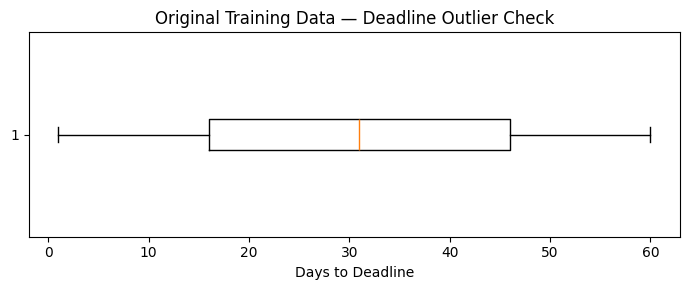

In [ ]:
import matplotlib.pyplot as plt

# Check deadlines in the original training data
days = pd.to_numeric(
    train_df["Days_To_Deadline"], errors="coerce"
)

print("Missing or nonnumeric deadlines:", days.isna().sum())
print("Negative deadlines:", (days < 0).sum())

# Calculate the IQR outlier boundaries
Q1 = days.quantile(0.25)
Q3 = days.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (days < lower_bound) | (days > upper_bound)

print("Lower boundary:", lower_bound)
print("Upper boundary:", upper_bound)
print("Potential outliers:", outlier_mask.sum())

# Draw a boxplot
plt.figure(figsize=(7, 3))
plt.boxplot(days.dropna(), vert=False)
plt.xlabel("Days to Deadline")
plt.title("Original Training Data — Deadline Outlier Check")
plt.tight_layout()
plt.show()

In [ ]:
# Keep one copy of each different question
project_df = (
    expanded_df.drop_duplicates(subset="Clean_Query")
    .copy()
    .reset_index(drop=True)
)

print("Different questions we will use:", len(project_df))
print("\nUrgency counts: 0 = Not Urgent, 1 = Urgent")
print(project_df["Urgent"].value_counts().sort_index())

Different questions we will use: 165

Urgency counts: 0 = Not Urgent, 1 = Urgent
Urgent
0    85
1    80
Name: count, dtype: int64


Questions: 165
Questions without a deadline: 30
Negative deadlines: 0
Lower boundary: -15.0
Upper boundary: 25.0
Potential outliers: 7


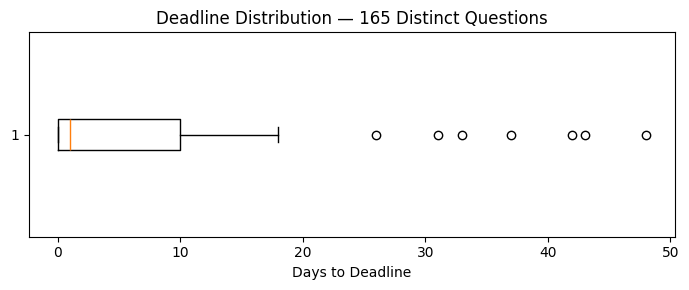

In [ ]:
import matplotlib.pyplot as plt

# Read deadlines as numbers
days = pd.to_numeric(
    project_df["Days_To_Deadline"], errors="coerce"
)

print("Questions:", len(project_df))
print("Questions without a deadline:", days.isna().sum())
print("Negative deadlines:", (days < 0).sum())

# Check for unusually small or large deadlines
Q1 = days.quantile(0.25)
Q3 = days.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = days[
    (days < lower_bound) | (days > upper_bound)
]

print("Lower boundary:", lower_bound)
print("Upper boundary:", upper_bound)
print("Potential outliers:", len(outliers))

# Show the deadline distribution
plt.figure(figsize=(7, 3))
plt.boxplot(days.dropna(), vert=False)
plt.xlabel("Days to Deadline")
plt.title("Deadline Distribution — 165 Distinct Questions")
plt.tight_layout()
plt.show()

In [ ]:
# Display records outside the IQR boundaries
flagged = project_df.loc[
    (days < lower_bound) | (days > upper_bound),
    [
        "Student_Query",
        "Days_To_Deadline",
        "Priority_Label",
        "Data_Source"
    ]
]

with pd.option_context("display.max_colwidth", None):
    display(flagged)

,Student_Query,Days_To_Deadline,Priority_Label,Data_Source
0,How to join student clubs?,31.0,Low,Original_supplied
1,My admit card has incorrect details.,48.0,High,Original_supplied
4,I cannot download my hall ticket for tomorrow's exam.,43.0,High,Original_supplied
5,Please share syllabus for Data Science course.,42.0,Low,Original_supplied
6,Request for internship approval letter.,26.0,Medium,Original_supplied
9,What is the hostel application procedure?,33.0,Low,Original_supplied
10,What are university working hours?,37.0,Low,Original_supplied


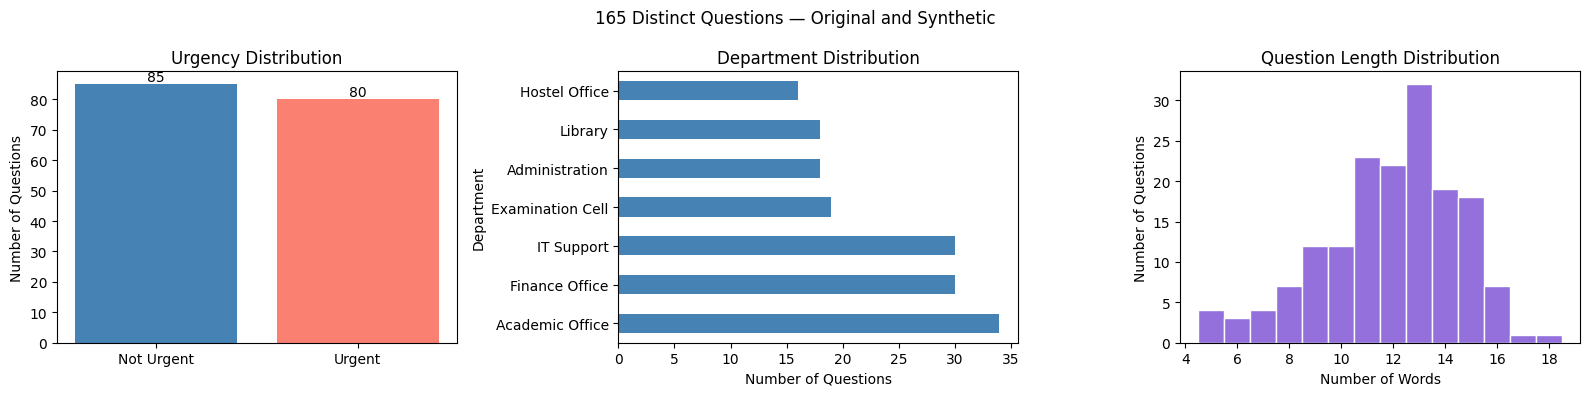

In [ ]:
import numpy as np

# Count words in each question
project_df["Query_Length"] = (
    project_df["Clean_Query"].str.split().str.len()
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Urgency distribution
counts = project_df["Urgent"].value_counts().reindex([0, 1])
bars = axes[0].bar(
    ["Not Urgent", "Urgent"],
    counts.values,
    color=["steelblue", "salmon"]
)
axes[0].bar_label(bars)
axes[0].set_title("Urgency Distribution")
axes[0].set_ylabel("Number of Questions")

# 2. Department distribution
project_df["Department"].value_counts().plot.barh(
    ax=axes[1], color="steelblue"
)
axes[1].set_title("Department Distribution")
axes[1].set_xlabel("Number of Questions")

# 3. Question lengths
lengths = project_df["Query_Length"]
bins = np.arange(lengths.min() - 0.5, lengths.max() + 1.5)

axes[2].hist(
    lengths, bins=bins,
    color="mediumpurple", edgecolor="white"
)
axes[2].set_title("Question Length Distribution")
axes[2].set_xlabel("Number of Words")
axes[2].set_ylabel("Number of Questions")

fig.suptitle("165 Distinct Questions — Original and Synthetic")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import StratifiedKFold

# Check that each scenario group has one urgency label
assert project_df["Scenario_Group"].notna().all()

assert (
    project_df.groupby("Scenario_Group")["Urgent"]
    .nunique().max() == 1
)

# One entry per scenario group
scenario_groups = (
    project_df[["Scenario_Group", "Urgent"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

splitter = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

project_folds = []

for train_idx, val_idx in splitter.split(
    scenario_groups["Scenario_Group"],
    scenario_groups["Urgent"]
):
    train_groups = scenario_groups.iloc[train_idx]["Scenario_Group"]
    val_groups = scenario_groups.iloc[val_idx]["Scenario_Group"]

    train_rows = np.flatnonzero(
        project_df["Scenario_Group"].isin(train_groups)
    )
    val_rows = np.flatnonzero(
        project_df["Scenario_Group"].isin(val_groups)
    )

    # Confirm that no scenario group appears on both sides
    assert set(train_groups).isdisjoint(set(val_groups))

    project_folds.append((train_rows, val_rows))

for number, (train_rows, val_rows) in enumerate(project_folds, 1):
    print(
        f"Split {number}: "
        f"{len(train_rows)} training, "
        f"{len(val_rows)} validation"
    )

Split 1: 130 training, 35 validation
Split 2: 136 training, 29 validation
Split 3: 132 training, 33 validation
Split 4: 134 training, 31 validation
Split 5: 128 training, 37 validation


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    make_scorer, precision_score, recall_score, f1_score
)

models = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", max_iter=1000
    ),
    "Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC(
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=5,
        random_state=42
    )
}

metrics = {
    "Accuracy": "accuracy",
    "Urgent precision": make_scorer(
        precision_score, zero_division=0
    ),
    "Urgent recall": make_scorer(
        recall_score, zero_division=0
    ),
    "Urgent F1": make_scorer(
        f1_score, zero_division=0
    )
}

comparison = []

for name, classifier in models.items():
    pipeline = make_pipeline(
        TfidfVectorizer(),
        classifier
    )

    scores = cross_validate(
        pipeline,
        project_df["Clean_Query"],
        project_df["Urgent"],
        cv=project_folds,
        scoring=metrics,
        error_score="raise"
    )

    row = {"Model": name}

    for metric in metrics:
        row[metric] = scores[f"test_{metric}"].mean() * 100

    comparison.append(row)

comparison_df = pd.DataFrame(comparison).set_index("Model")

print("Average grouped cross-validation results (%)")
display(comparison_df.round(2))

Average grouped cross-validation results (%)


,Accuracy,Urgent precision,Urgent recall,Urgent F1
Model,,,,
Baseline,47.38,8.00,20.00,11.43
Logistic Regression,95.46,92.24,98.57,95.18
Naive Bayes,94.71,95.14,94.31,94.56
Linear SVM,96.49,95.23,97.32,96.20
Decision Tree,85.90,93.14,79.19,84.23


In [ ]:
from sklearn.model_selection import GridSearchCV

# Connect TF-IDF to logistic regression
tuning_pipeline = make_pipeline(
    TfidfVectorizer(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000
    )
)

# Try eight combinations of TF-IDF settings
parameter_grid = {
    "tfidfvectorizer__ngram_range": [(1, 1), (1, 2)],
    "tfidfvectorizer__stop_words": [None, "english"],
    "tfidfvectorizer__max_features": [100, None]
}

grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=parameter_grid,
    scoring=metrics,
    refit="Urgent F1",
    cv=project_folds,
    n_jobs=-1,
    error_score="raise"
)

grid_search.fit(
    project_df["Clean_Query"],
    project_df["Urgent"]
)

print("Selected settings:")
print(grid_search.best_params_)

print(
    "\nBest mean tuning F1:",
    f"{grid_search.best_score_:.2%}"
)

# Display the five highest-scoring combinations
tuning_results = pd.DataFrame(grid_search.cv_results_)

display(
    tuning_results[
        [
            "param_tfidfvectorizer__ngram_range",
            "param_tfidfvectorizer__stop_words",
            "param_tfidfvectorizer__max_features",
            "mean_test_Urgent F1",
            "mean_test_Urgent recall"
        ]
    ]
    .sort_values("mean_test_Urgent F1", ascending=False)
    .head()
)

Selected settings:
{'tfidfvectorizer__max_features': None, 'tfidfvectorizer__ngram_range': (1, 1), 'tfidfvectorizer__stop_words': None}

Best mean tuning F1: 95.18%


,param_tfidfvectorizer__ngram_range,param_tfidfvectorizer__stop_words,param_tfidfvectorizer__max_features,mean_test_Urgent F1,mean_test_Urgent recall
4,"(1, 1)",None,None,0.951810,0.985714
6,"(1, 2)",None,None,0.944774,0.962103
2,"(1, 2)",None,100,0.924084,0.947817
5,"(1, 1)",english,None,0.908892,0.906746
7,"(1, 2)",english,None,0.908892,0.906746


In [ ]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score

nested_results = []
nested_predictions = np.full(len(project_df), -1)

for fold, (train_rows, val_rows) in enumerate(project_folds, 1):
    training = project_df.iloc[train_rows].reset_index(drop=True)
    validation = project_df.iloc[val_rows]

    # Build three inner splits using training groups only
    inner_groups = (
        training[["Scenario_Group", "Urgent"]]
        .drop_duplicates()
        .reset_index(drop=True)
    )

    inner_splitter = StratifiedKFold(
        n_splits=3, shuffle=True, random_state=42
    )

    inner_folds = []

    for inner_train, inner_val in inner_splitter.split(
        inner_groups["Scenario_Group"],
        inner_groups["Urgent"]
    ):
        train_groups = inner_groups.iloc[inner_train]["Scenario_Group"]
        val_groups = inner_groups.iloc[inner_val]["Scenario_Group"]

        inner_folds.append((
            np.flatnonzero(
                training["Scenario_Group"].isin(train_groups)
            ),
            np.flatnonzero(
                training["Scenario_Group"].isin(val_groups)
            )
        ))

    # Choose settings without seeing the outer validation questions
    search = GridSearchCV(
        clone(tuning_pipeline),
        parameter_grid,
        scoring=metrics,
        refit="Urgent F1",
        cv=inner_folds,
        n_jobs=-1,
        error_score="raise"
    )

    search.fit(training["Clean_Query"], training["Urgent"])

    predictions = search.predict(validation["Clean_Query"])
    nested_predictions[val_rows] = predictions
    actual = validation["Urgent"]

    nested_results.append({
        "Fold": fold,
        "Accuracy": accuracy_score(actual, predictions),
        "Urgent precision": precision_score(
            actual, predictions, zero_division=0
        ),
        "Urgent recall": recall_score(
            actual, predictions, zero_division=0
        ),
        "Urgent F1": f1_score(
            actual, predictions, zero_division=0
        )
    })

    print(f"Fold {fold} completed")

nested_results_df = pd.DataFrame(nested_results).set_index("Fold")

print("\nNested validation results (%)")
display((nested_results_df * 100).round(2))

print("\nAverage results (%)")
display((nested_results_df.mean() * 100).round(2))

Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed

Nested validation results (%)


,Accuracy,Urgent precision,Urgent recall,Urgent F1
Fold,,,,
1,85.71,76.47,92.86,83.87
2,100.00,100.00,100.00,100.00
3,96.97,94.74,100.00,97.30
4,100.00,100.00,100.00,100.00
5,94.59,90.00,100.00,94.74



Average results (%)


,0
Accuracy,95.46
Urgent precision,92.24
Urgent recall,98.57
Urgent F1,95.18


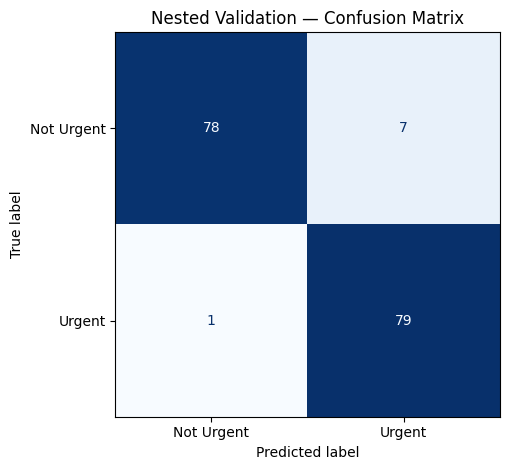

Total incorrect predictions: 8


,Student_Query,Data_Source,Actual,Predicted
7,LMS is not allowing assignment upload.,Original_supplied,Not Urgent,Urgent
36,I need an installment approval today to avoid being dropped from all classes.,Synthetic_AI,Urgent,Not Urgent
108,My refund request has the wrong bank details and the review is in ten days.,Synthetic_AI,Not Urgent,Urgent
109,Please update the account number on my refund application before the ten-day cutoff.,Synthetic_AI,Not Urgent,Urgent
116,My academic software license fails to activate and the assignment is due two weeks from now.,Synthetic_AI,Not Urgent,Urgent
119,I have a week to restore portal access before I select my classes.,Synthetic_AI,Not Urgent,Urgent
122,I cannot save my research files and the submission deadline is ten days away.,Synthetic_AI,Not Urgent,Urgent
132,My student card has a spelling error and I need a corrected one next week.,Synthetic_AI,Not Urgent,Urgent


In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

# Confirm every question received a validation prediction
assert (nested_predictions != -1).all()

# Plot predictions made when each scenario group was held out
ConfusionMatrixDisplay.from_predictions(
    project_df["Urgent"],
    nested_predictions,
    labels=[0, 1],
    display_labels=["Not Urgent", "Urgent"],
    cmap="Blues",
    colorbar=False
)

plt.title("Nested Validation — Confusion Matrix")
plt.tight_layout()
plt.show()

# Display incorrectly classified questions
error_results = project_df[
    ["Student_Query", "Data_Source", "Urgent"]
].copy()

error_results["Predicted"] = nested_predictions

mistakes = error_results[
    error_results["Urgent"] != error_results["Predicted"]
].copy()

label_names = {0: "Not Urgent", 1: "Urgent"}
mistakes["Urgent"] = mistakes["Urgent"].map(label_names)
mistakes["Predicted"] = mistakes["Predicted"].map(label_names)

print("Total incorrect predictions:", len(mistakes))

with pd.option_context("display.max_colwidth", None):
    display(mistakes.rename(columns={"Urgent": "Actual"}))

In [ ]:
# GridSearchCV already refitted its selected model on all 165 questions
final_model = grid_search.best_estimator_

print("Final model ready.")
print("Training questions:", len(project_df))

# Print each selected setting on a separate line
for setting, value in grid_search.best_params_.items():
    print(setting, "=", value)

Final model ready.
Training questions: 165
tfidfvectorizer__max_features = None
tfidfvectorizer__ngram_range = (1, 1)
tfidfvectorizer__stop_words = None


In [ ]:
# Convert the 165 questions using the fitted TF-IDF converter
tfidf_matrix = final_model.named_steps[
    "tfidfvectorizer"
].transform(project_df["Clean_Query"])

# Storage used by the sparse matrix's numerical buffers
sparse_bytes = (
    tfidf_matrix.data.nbytes
    + tfidf_matrix.indices.nbytes
    + tfidf_matrix.indptr.nbytes
)

# Estimate dense storage without creating a dense matrix
dense_bytes = (
    tfidf_matrix.shape[0]
    * tfidf_matrix.shape[1]
    * tfidf_matrix.dtype.itemsize
)

print("Matrix shape:", tfidf_matrix.shape)
print("Sparse storage:", round(sparse_bytes / 1024, 2), "KiB")
print("Equivalent dense storage:", round(dense_bytes / 1024, 2), "KiB")
print(
    "Storage reduction:",
    f"{(1 - sparse_bytes / dense_bytes) * 100:.2f}%"
)

Matrix shape: (165, 551)
Sparse storage: 22.14 KiB
Equivalent dense storage: 710.27 KiB
Storage reduction: 96.88%


In [ ]:
question = input("Enter a university question in English: ")
clean_question = " ".join(question.lower().split())

if not clean_question:
    print("Please enter a question.")
else:
    # Check whether any words match the learned vocabulary
    features = final_model.named_steps[
        "tfidfvectorizer"
    ].transform([clean_question])

    if features.nnz == 0:
        print("No recognized words. Please request human review.")
    else:
        prediction = final_model.predict([clean_question])[0]
        label = "Urgent" if prediction == 1 else "Not Urgent"
        print("Predicted priority:", label)

Enter a university question in English: My final exam begins in twenty minutes and my account is locked 
Predicted priority: Urgent


In [ ]:

from sklearn.metrics import classification_report, accuracy_score

# Predict the supplied test questions
test_predictions = final_model.predict(test_df["Clean_Query"])

print(
    "Supplied-test accuracy:",
    f"{accuracy_score(test_df['Urgent'], test_predictions):.2%}"
)

print(classification_report(
    test_df["Urgent"],
    test_predictions,
    labels=[0, 1],
    target_names=["Not Urgent", "Urgent"],
    zero_division=0
))

print(
    "Note: all 15 test question texts also appear in training. "
    "This evaluates familiar wording, not unseen questions."
)

Supplied-test accuracy: 100.00%
              precision    recall  f1-score   support

  Not Urgent       1.00      1.00      1.00       671
      Urgent       1.00      1.00      1.00       329

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000

Note: all 15 test question texts also appear in training. This evaluates familiar wording, not unseen questions.
